# Figures and tables

**Checking `results` directory**

In [1]:
!./5_check_results.py


1.1 z-threshold

✅ z_thresholds_best.json file found.

1.1 z-threshold

Task               f1       auc        acc       
-----------------------------------------------
healthy_vs_cancer  ✅        ✅          ✅         
cancer_vs_lr_hr    ✅        ✅          ✅         
MC                 ✅        ✅          ✅         

1.2 Mask-analysis

Task               Model    f1         auc        acc       
--------------------------------------------------------
healthy_vs_cancer  svm      ✅          ✅          ✅         
healthy_vs_cancer  rf       ✅          ✅          ✅         
healthy_vs_cancer  lr       ✅          ✅          ✅         
cancer_vs_lr_hr    svm      ✅          ✅          ✅         
cancer_vs_lr_hr    rf       ✅          ✅          ✅         
cancer_vs_lr_hr    lr       ✅          ✅          ✅         
MC                 svm      ✅          ✅          ✅         
MC                 rf       ✅          ✅          ✅         
MC                 lr       ✅          ✅          ✅  

**1.3 Frequency fold rankings**

In [2]:
# coloring IIVV paper
from toolbox.visualization import cmap_gradient, plot_freq_rank_heatmap

task='healthy_vs_cancer', metric='f1'


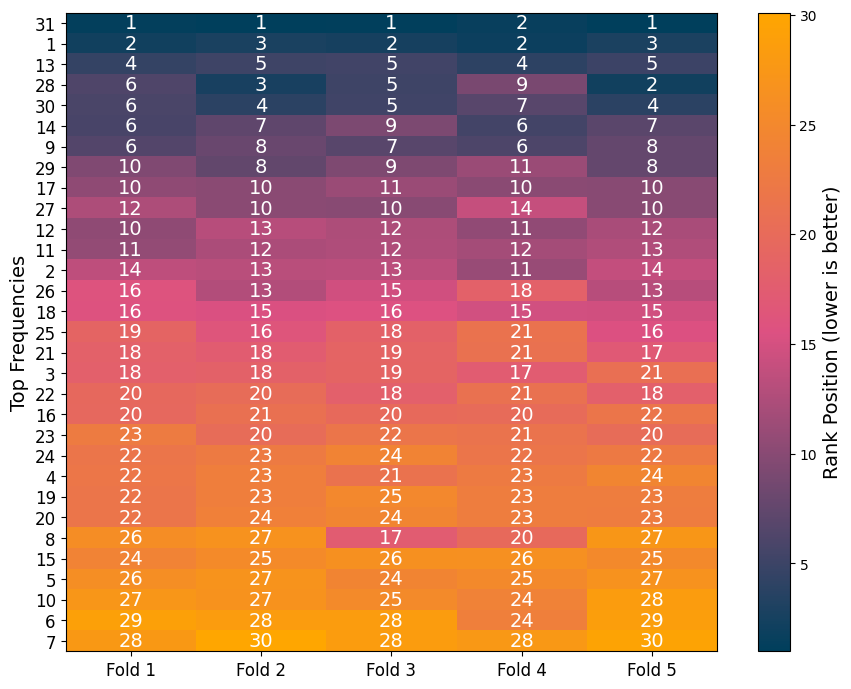

task='healthy_vs_cancer', metric='auc'


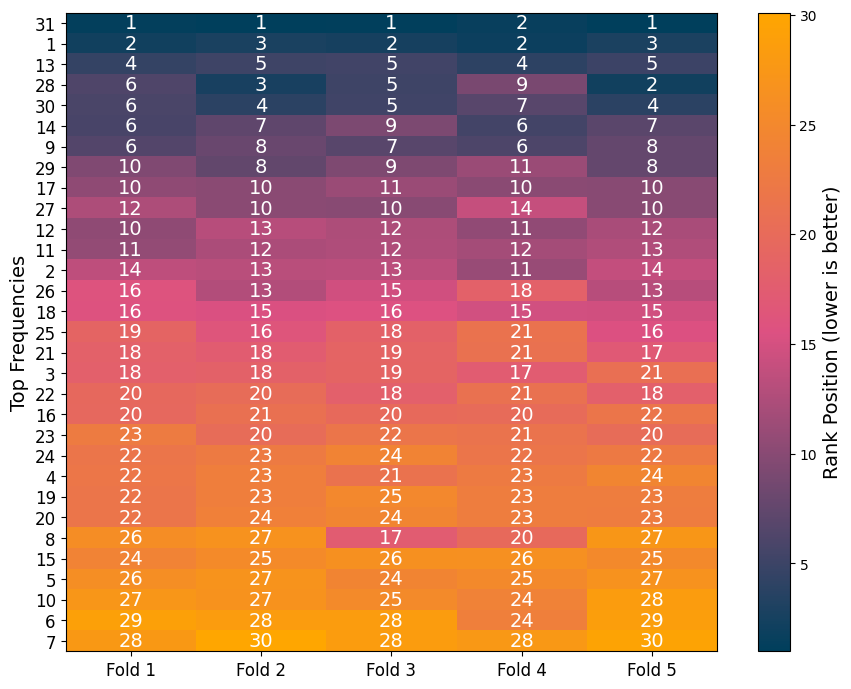

task='healthy_vs_cancer', metric='acc'


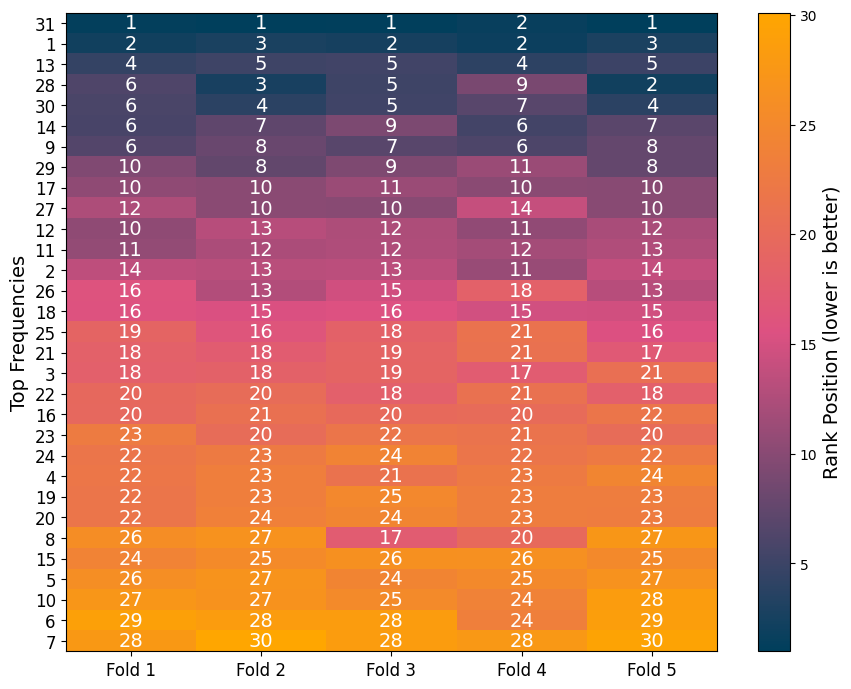

task='cancer_vs_lr_hr', metric='f1'


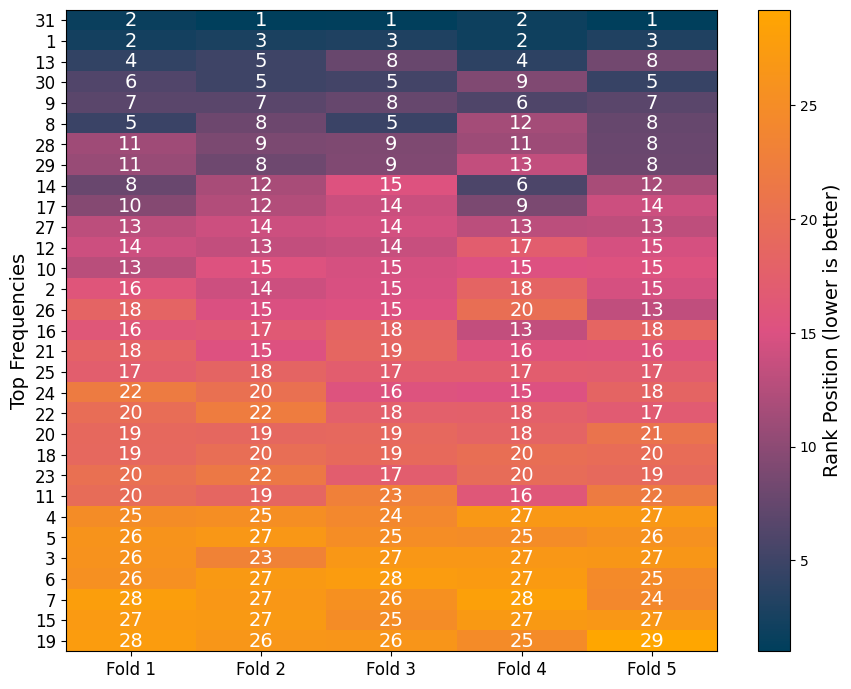

task='cancer_vs_lr_hr', metric='auc'


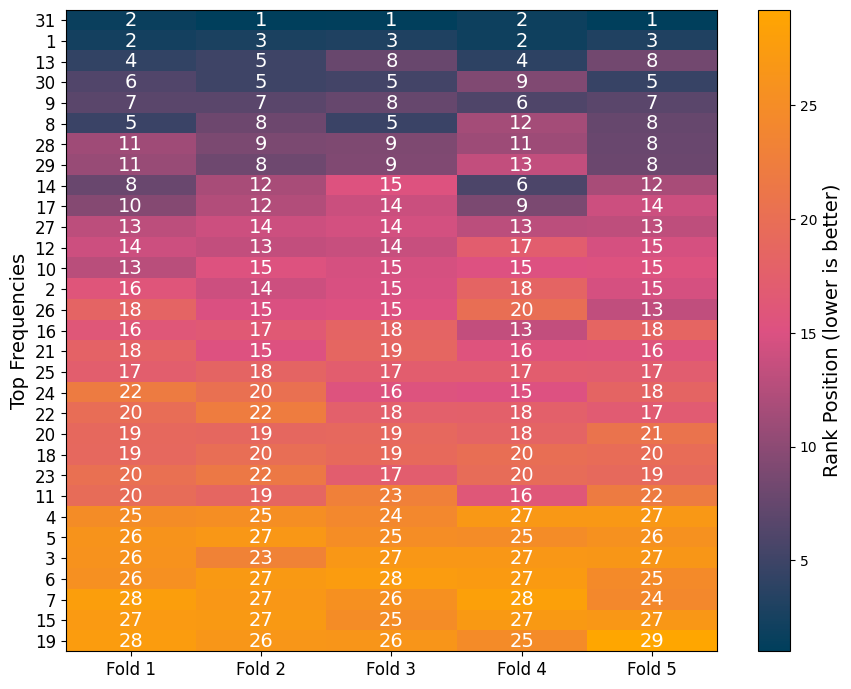

task='cancer_vs_lr_hr', metric='acc'


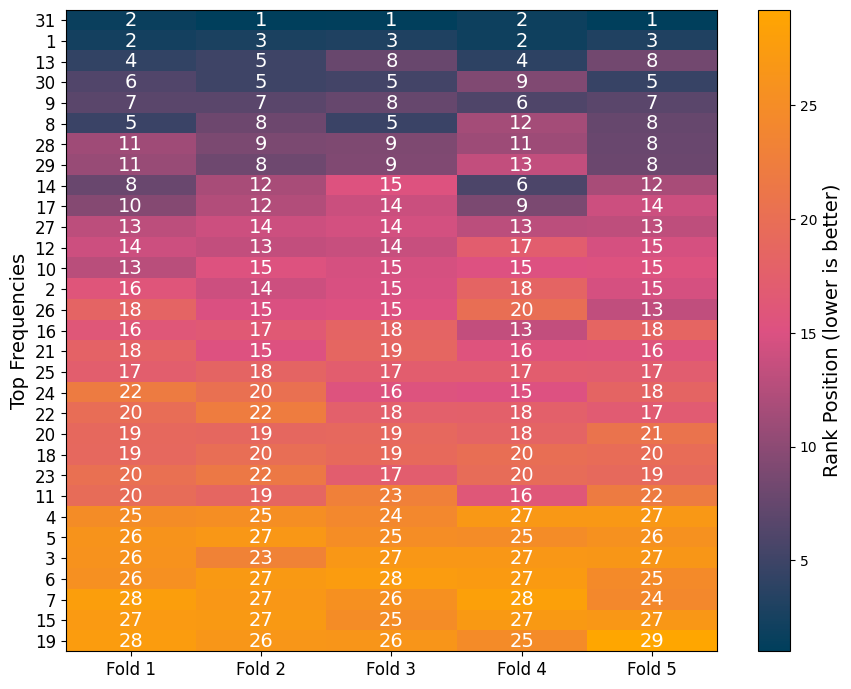

task='MC', metric='f1'


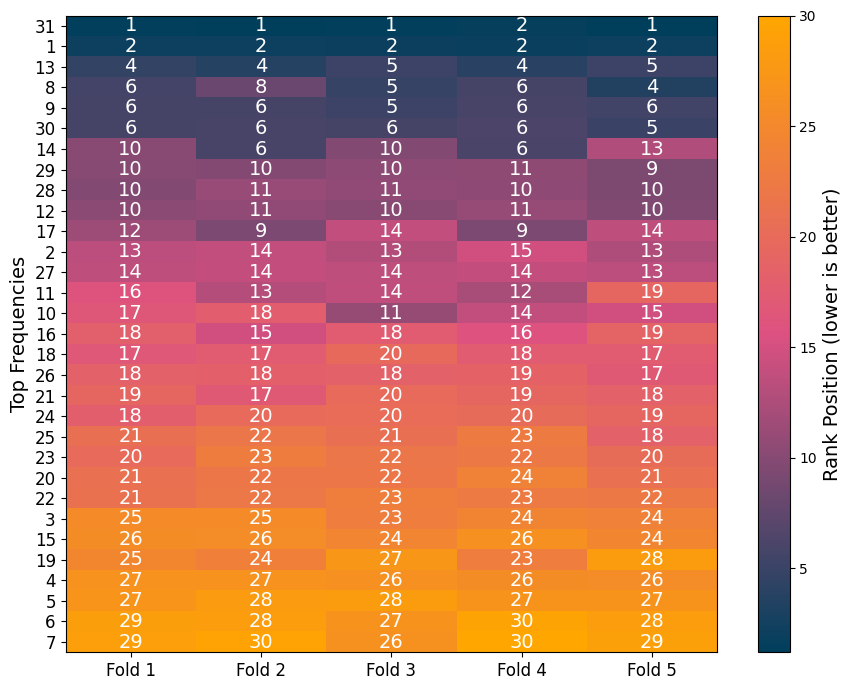

task='MC', metric='auc'


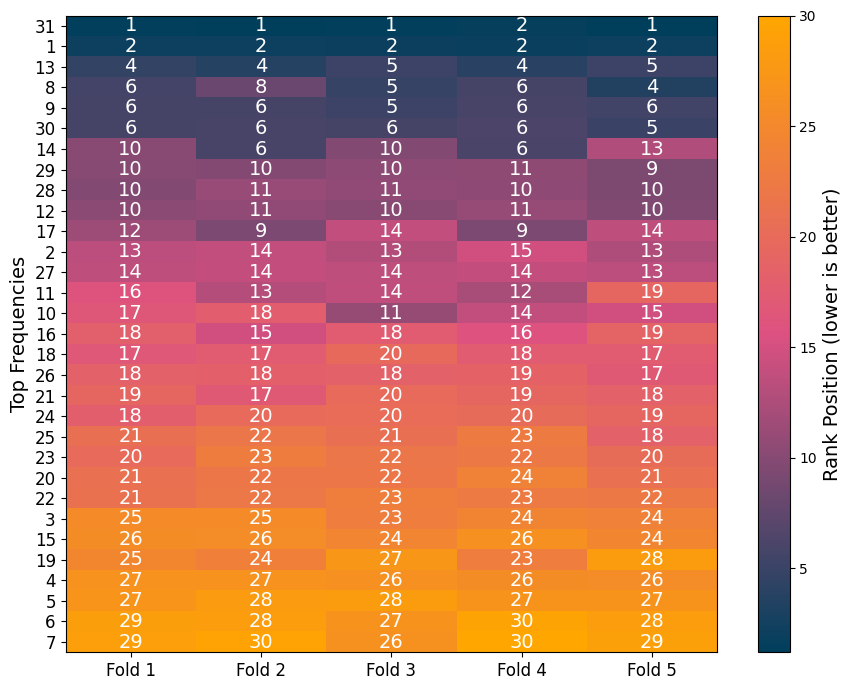

task='MC', metric='acc'


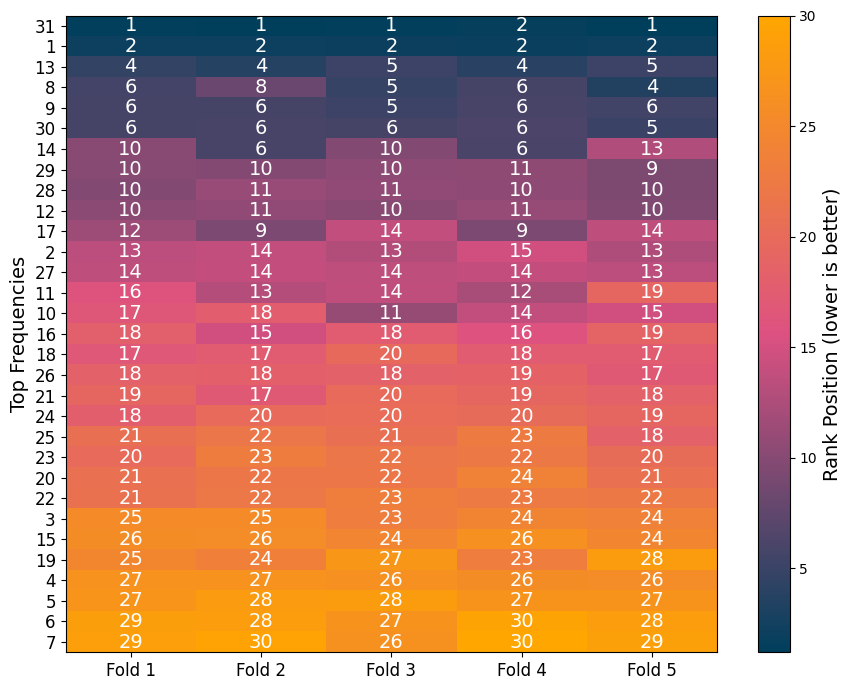

In [3]:
class_tasks = ["healthy_vs_cancer", "cancer_vs_lr_hr", "MC"]

metrics = [
    "f1",
    "auc",
    "acc",
]

for task in class_tasks:
    for metric in metrics:
        print(f"{task=}, {metric=}")
        plot_freq_rank_heatmap(task, metric, cmap=cmap_gradient)
# plot_freq_rank_heatmap("healthy_vs_cancer", "f1", cmap=cmap_gradient)

**1.3 Number of top frequencies**

In [4]:
from toolbox.visualization import plot_fold_means_with_error, plot_mean_across_folds

task='healthy_vs_cancer', metric='f1'


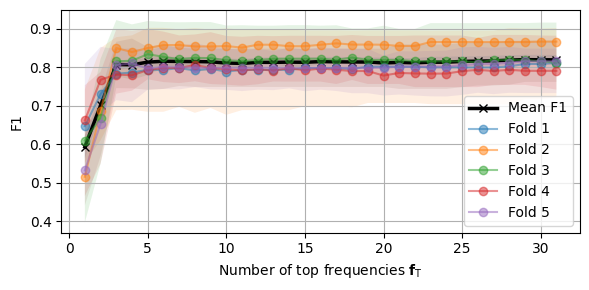

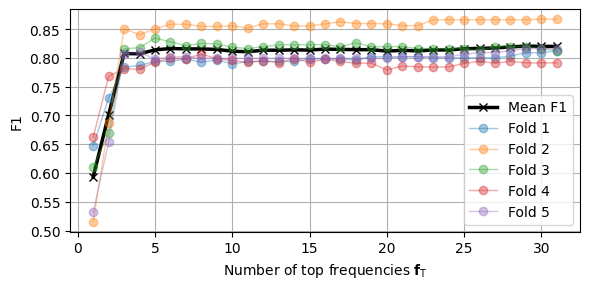

task='healthy_vs_cancer', metric='auc'


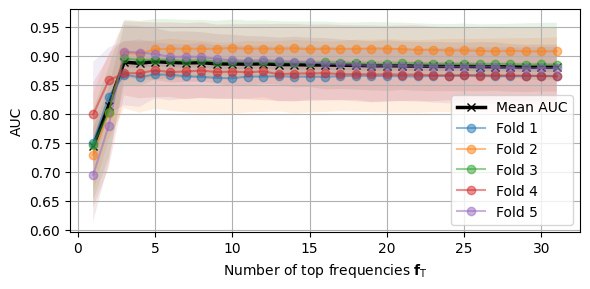

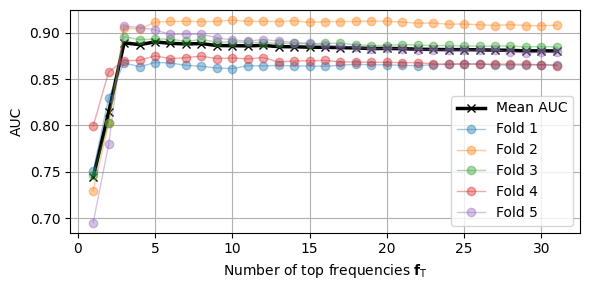

task='healthy_vs_cancer', metric='acc'


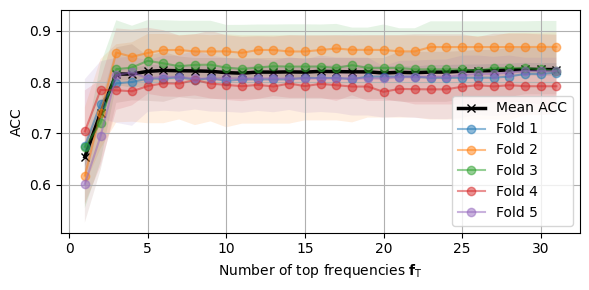

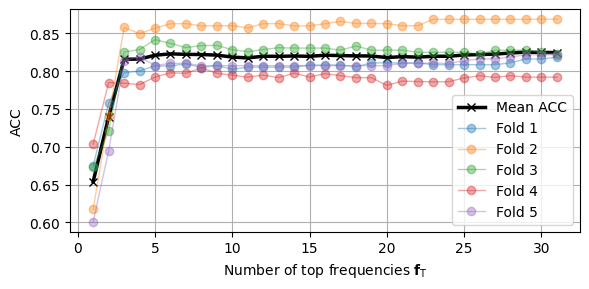

task='cancer_vs_lr_hr', metric='f1'


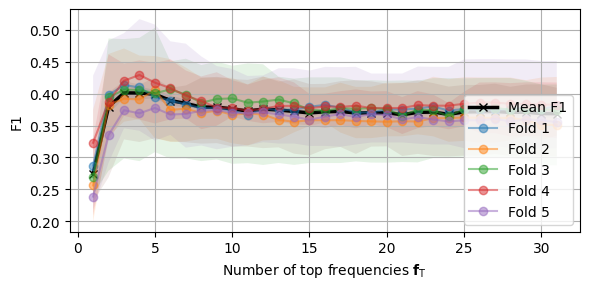

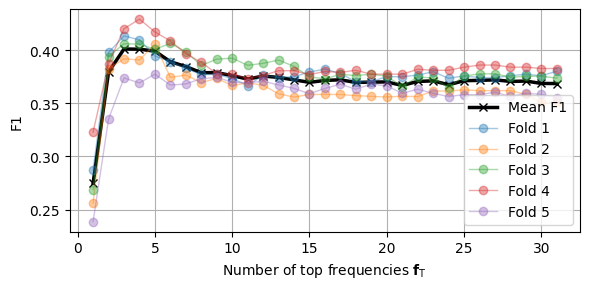

task='cancer_vs_lr_hr', metric='auc'


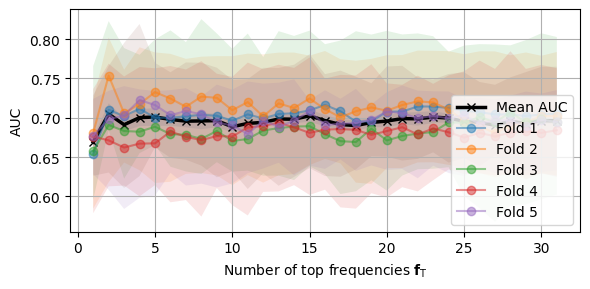

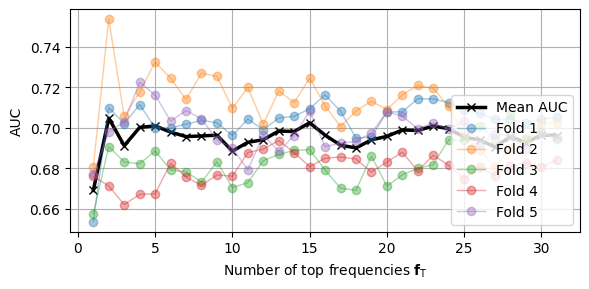

task='cancer_vs_lr_hr', metric='acc'


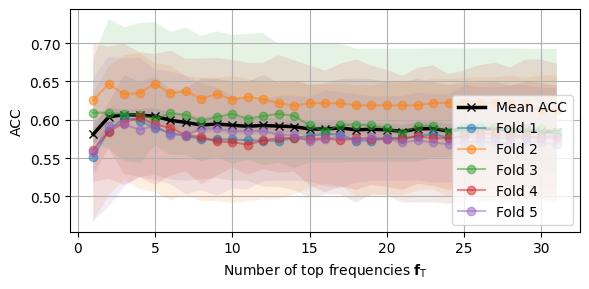

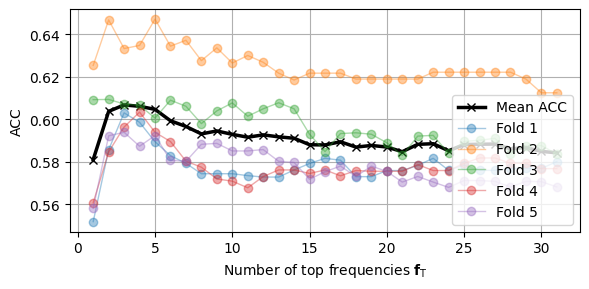

task='MC', metric='f1'


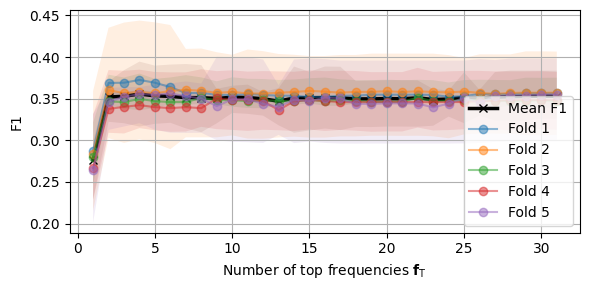

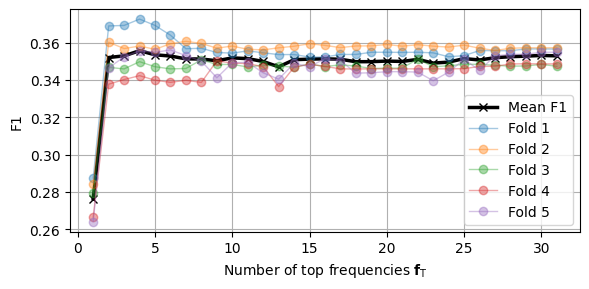

task='MC', metric='auc'


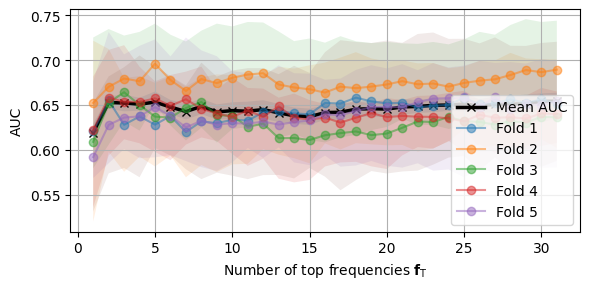

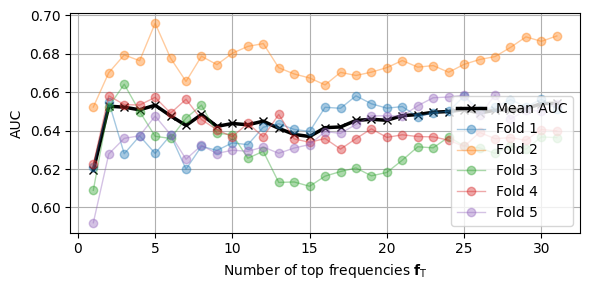

task='MC', metric='acc'


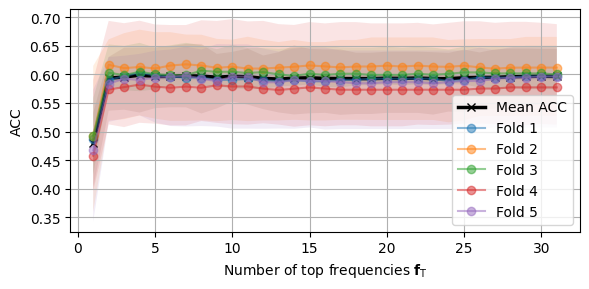

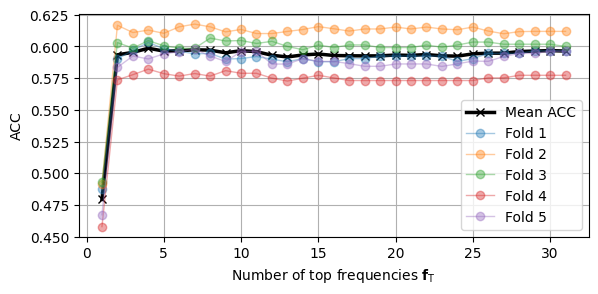

In [5]:
class_tasks = ["healthy_vs_cancer", "cancer_vs_lr_hr", "MC"]

metrics = [
    "f1",
    "auc",
    "acc",
]

for task in class_tasks:
    for metric in metrics:
        print(f"{task=}, {metric=}")
        plot_fold_means_with_error(task, metric, error="std")
        plot_mean_across_folds(task, metric)

## IIVV paper plots and tables

**Table VII**

In [6]:
import json
from pathlib import Path

import pandas as pd

RESULTS_DIR = Path("results")  # adjust if needed

TASKS = ["healthy_vs_cancer", "cancer_vs_lr_hr", "MC"]
TASK_LABELS = {
    "healthy_vs_cancer": "HvsC",
    "cancer_vs_lr_hr": "CvLRHR",
    "MC": "MC",
}

MODELS = ["svm", "rf", "lr"]
MODEL_LABELS = {"svm": "SVM", "rf": "RF", "lr": "LR"}


def load_baseline_summary(task: str) -> dict:
    fp = RESULTS_DIR / f"BASELINE_summary_{task}.json"
    if not fp.exists():
        raise FileNotFoundError(f"Missing: {fp.resolve()}")
    return json.loads(fp.read_text(encoding="utf-8"))


def get_metrics(summary: dict, model: str):
    m = summary["models"].get(model)
    if m is None:
        return None
    return {
        "f1": float(m.get("f1_mean", float("nan"))),
        "acc": float(m.get("accuracy_mean", float("nan"))),
        "auc": float(m.get("auc_mean", float("nan"))),
        "recall": float(m.get("recall_mean", float("nan"))),
        "precision": float(m.get("precision_mean", float("nan"))),
    }


summaries = {t: load_baseline_summary(t) for t in TASKS}

cols = []
for t in TASKS:
    cols += [(t, "f1"), (t, "acc"), (t, "auc"), (t, "recall"), (t, "precision")]

df = pd.DataFrame(
    index=[MODEL_LABELS[m] for m in MODELS], columns=pd.MultiIndex.from_tuples(cols)
)

for m in MODELS:
    for t in TASKS:
        met = get_metrics(summaries[t], m)
        if met is None:
            df.loc[MODEL_LABELS[m], (t, "f1")] = float("nan")
            df.loc[MODEL_LABELS[m], (t, "acc")] = float("nan")
            df.loc[MODEL_LABELS[m], (t, "auc")] = float("nan")
            df.loc[MODEL_LABELS[m], (t, "recall")] = float("nan")
            df.loc[MODEL_LABELS[m], (t, "precision")] = float("nan")
        else:
            df.loc[MODEL_LABELS[m], (t, "f1")] = met["f1"]
            df.loc[MODEL_LABELS[m], (t, "acc")] = met["acc"]
            df.loc[MODEL_LABELS[m], (t, "auc")] = met["auc"]
            df.loc[MODEL_LABELS[m], (t, "recall")] = met["recall"]
            df.loc[MODEL_LABELS[m], (t, "precision")] = met["precision"]

print(
    "Baseline results for Table VII. None of the models are tuned. Just the default Scikit-learn implemented models."
)
df = df.astype(float)

pd.options.display.float_format = "{:,.2f}".format
df

Baseline results for Table VII. None of the models are tuned. Just the default Scikit-learn implemented models.


healthy_vs_cancer                            cancer_vs_lr_hr            \
                   f1  acc  auc recall precision              f1  acc  auc   
SVM              0.81 0.82 0.88   0.81      0.81            0.37 0.59 0.74   
RF               0.81 0.81 0.88   0.83      0.80            0.46 0.60 0.75   
LR               0.77 0.78 0.82   0.79      0.77            0.45 0.58 0.68   

                       MC                             
    recall precision   f1  acc  auc recall precision  
SVM   0.40      0.35 0.35 0.59 0.72   0.41      0.31  
RF    0.47      0.46 0.40 0.59 0.76   0.43      0.41  
LR    0.46      0.46 0.40 0.53 0.65   0.41      0.40

**Final results of the tuned models**

In [7]:
from __future__ import annotations
from pathlib import Path
from typing import Dict, List

import pandas as pd

ROOT_DIR = Path("results")  # ggf. anpassen
WANTED_COLS = ["accuracy", "f1", "auc", "recall", "specificity"]


def discover_metrics_csvs(root: Path) -> Dict[str, Dict[str, Path]]:
    files: Dict[str, Dict[str, Path]] = {}
    for fp in root.rglob("METRICS_*_*.csv"):
        stem = fp.stem.replace("METRICS_", "")
        if "_" not in stem:
            continue
        task, metric = stem.rsplit("_", 1)
        files.setdefault(task, {})[metric] = fp
    return files


def build_table(files_by_task: Dict[str, Dict[str, Path]]) -> pd.DataFrame:
    rows: List[pd.DataFrame] = []

    for task, metrics_map in files_by_task.items():
        for metric, fp in metrics_map.items():
            df = pd.read_csv(fp)

            cols = [c for c in WANTED_COLS if c in df.columns]
            df = df[cols + (["model"] if "model" in df.columns else [])]

            df["tuned task"] = task
            df["tuning metric"] = metric

            if "model" in df.columns:
                df = df.set_index(["tuned task", "tuning metric", "model"])
            else:
                df = df.set_index(["tuned task", "tuning metric"])

            rows.append(df)

    if not rows:
        raise ValueError("No metric files found.")

    return pd.concat(rows).sort_index()


# ---- usage ----
files = discover_metrics_csvs(ROOT_DIR)
table = build_table(files)

pd.options.display.float_format = "{:,.4f}".format
table

accuracy     f1    auc  recall  \
tuned task            tuning metric  model                                   
MC_lr                 acc            lr       0.5781 0.3629 0.7034  0.4064   
                      auc            lr       0.5898 0.3410 0.7578  0.4052   
                      f1             lr       0.4961 0.3653 0.6560  0.3726   
MC_rf                 acc            rf       0.5977 0.4021 0.7363  0.4313   
                      auc            rf       0.6016 0.4295 0.7756  0.4470   
                      f1             rf       0.6055 0.4482 0.7254  0.4591   
MC_svm                acc            svm      0.6055 0.3517 0.7062  0.4167   
                      auc            svm      0.5781 0.3354 0.7404  0.3974   
                      f1             svm      0.5469 0.3415 0.6074  0.3858   
cancer_vs_lr_hr_lr    acc            lr       0.6205 0.4283 0.7616  0.4350   
                      acc-checkpoint lr       0.6205 0.4283 0.7616  0.4350   
                      auc            lr       0.6446 0.4493 0.7684  0.4523   
                      f1             lr       0.6325 0.5055 0.7529  0.4986   
cancer_vs_lr_hr_rf    acc            rf       0.5602 0.4305 0.7126  0.4303   
                      acc-checkpoint rf       0.5602 0.4305 0.7126  0.4303   
                      auc            rf       0.5964 0.4656 0.7669  0.4672   
                      f1             rf       0.5783 0.4562 0.7166  0.4547   
cancer_vs_lr_hr_svm   acc            svm      0.5663 0.2410 0.5008  0.3264   
                      acc-checkpoint svm      0.5663 0.2410 0.5008  0.3264   
                      auc            svm      0.6446 0.5001 0.7633  0.4929   
                      f1             svm      0.5904 0.4115 0.7554  0.4202   
healthy_vs_cancer_lr  acc            lr       0.8011 0.7886 0.8318  0.7667   
                      auc            lr       0.8011 0.7886 0.9015  0.7667   
                      auc-checkpoint lr       0.8011 0.7886 0.9015  0.7667   
                      f1             lr       0.8065 0.7955 0.8749  0.7778   
healthy_vs_cancer_rf  acc            rf       0.8011 0.8000 0.8769  0.8222   
                      auc            rf       0.8065 0.7978 0.8911  0.7889   
                      f1             rf       0.8118 0.8087 0.8778  0.8222   
healthy_vs_cancer_svm acc            svm      0.8280 0.8261 0.8420  0.8444   
                      auc            svm      0.8172 0.8152 0.9006  0.8333   
                      f1             svm      0.8011 0.8122 0.8667  0.8889   

                                            specificity  
tuned task            tuning metric  model               
MC_lr                 acc            lr             NaN  
                      auc            lr             NaN  
                      f1             lr             NaN  
MC_rf                 acc            rf             NaN  
                      auc            rf             NaN  
                      f1             rf             NaN  
MC_svm                acc            svm            NaN  
                      auc            svm            NaN  
                      f1             svm            NaN  
cancer_vs_lr_hr_lr    acc            lr             NaN  
                      acc-checkpoint lr             NaN  
                      auc            lr             NaN  
                      f1             lr             NaN  
cancer_vs_lr_hr_rf    acc            rf             NaN  
                      acc-checkpoint rf             NaN  
                      auc            rf             NaN  
                      f1             rf             NaN  
cancer_vs_lr_hr_svm   acc            svm            NaN  
                      acc-checkpoint svm            NaN  
                      auc            svm            NaN  
                      f1             svm            NaN  
healthy_vs_cancer_lr  acc            lr          0.8333  
                      auc            lr          0.8333  
                   

___